## Eksplorasi Data IHSG dan Variabel Makroekonomi

Notebook ini bertujuan untuk melakukan analisis eksploratif terhadap data
Indeks Harga Saham Gabungan (IHSG) dan variabel makroekonomi yang digunakan
dalam penelitian, guna memahami pola data serta hubungan antar variabel
sebelum tahap pemodelan LSTM.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

final_df = pd.read_csv("../data/processed/dataset_final.csv", parse_dates=["date"])

In [2]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2426 entries, 0 to 2425
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         2426 non-null   datetime64[ns]
 1   ihsg         2426 non-null   float64       
 2   nilai_tukar  2426 non-null   float64       
 3   suku_bunga   2426 non-null   float64       
 4   inflasi      2426 non-null   float64       
 5   pdb          2426 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 113.8 KB


#### Load Data

In [3]:
final_df.head()

,date,ihsg,nilai_tukar,suku_bunga,inflasi,pdb
0,2015-01-02,5242.77,12542.5,7.75,-0.24,2.15804
1,2015-01-05,5219.99,12627.5,7.75,-0.24,2.15804
2,2015-01-06,5169.06,12657.5,7.75,-0.24,2.15804
3,2015-01-07,5207.12,12738.5,7.75,-0.24,2.15804
4,2015-01-08,5211.83,12680.0,7.75,-0.24,2.15804


Statistik deskriptif di sini digunakan untuk memberikan gambaran umum mengenai
karakteristik data IHSG dan variabel makroekonomi, termasuk nilai rata-rata,
sebaran data, serta rentang nilai selama periode pengamatan.

In [4]:
final_df.describe()

,date,ihsg,nilai_tukar,suku_bunga,inflasi,pdb
count,2426,2426.000000,2426.000000,2426.000000,2426.000000,2426.000000
mean,2019-12-29 21:01:55.746084096,6063.931603,14318.754575,5.245672,0.232692,2.711739
min,2015-01-02 00:00:00,3937.630000,12472.500000,3.500000,-0.450000,2.158040
25%,2017-07-05 06:00:00,5386.112500,13553.875000,4.250000,0.030000,2.498698
50%,2019-12-31 12:00:00,6107.380000,14250.000000,5.250000,0.190000,2.709722
75%,2022-07-03 06:00:00,6786.620000,14905.000000,6.000000,0.390000,2.961564
max,2024-12-30 00:00:00,7905.390000,16575.000000,7.750000,1.170000,3.296742
std,NaN,844.270823,883.445286,1.237507,0.293419,0.300804


#### Visualisasi Time Series

IHSG

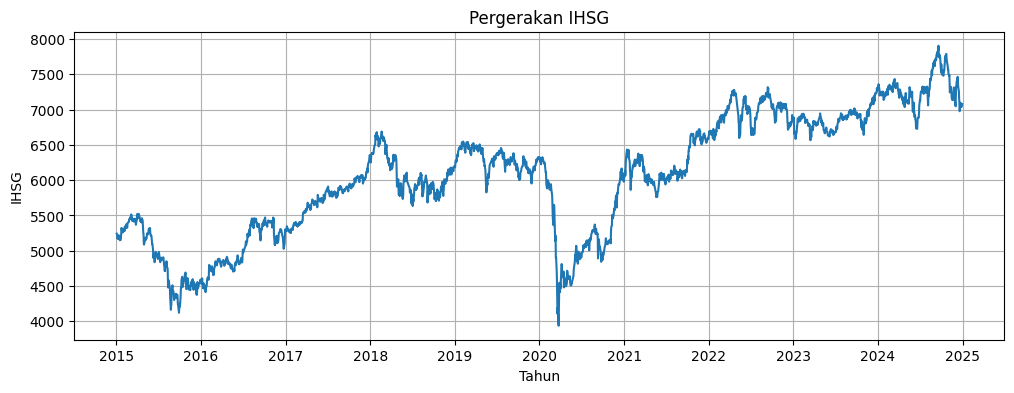

In [5]:
plt.figure(figsize=(12,4))
plt.plot(final_df["date"], final_df["ihsg"])
plt.title("Pergerakan IHSG")
plt.xlabel("Tahun")
plt.ylabel("IHSG")
plt.grid(True)
plt.show()

Variabel Makroekonomi

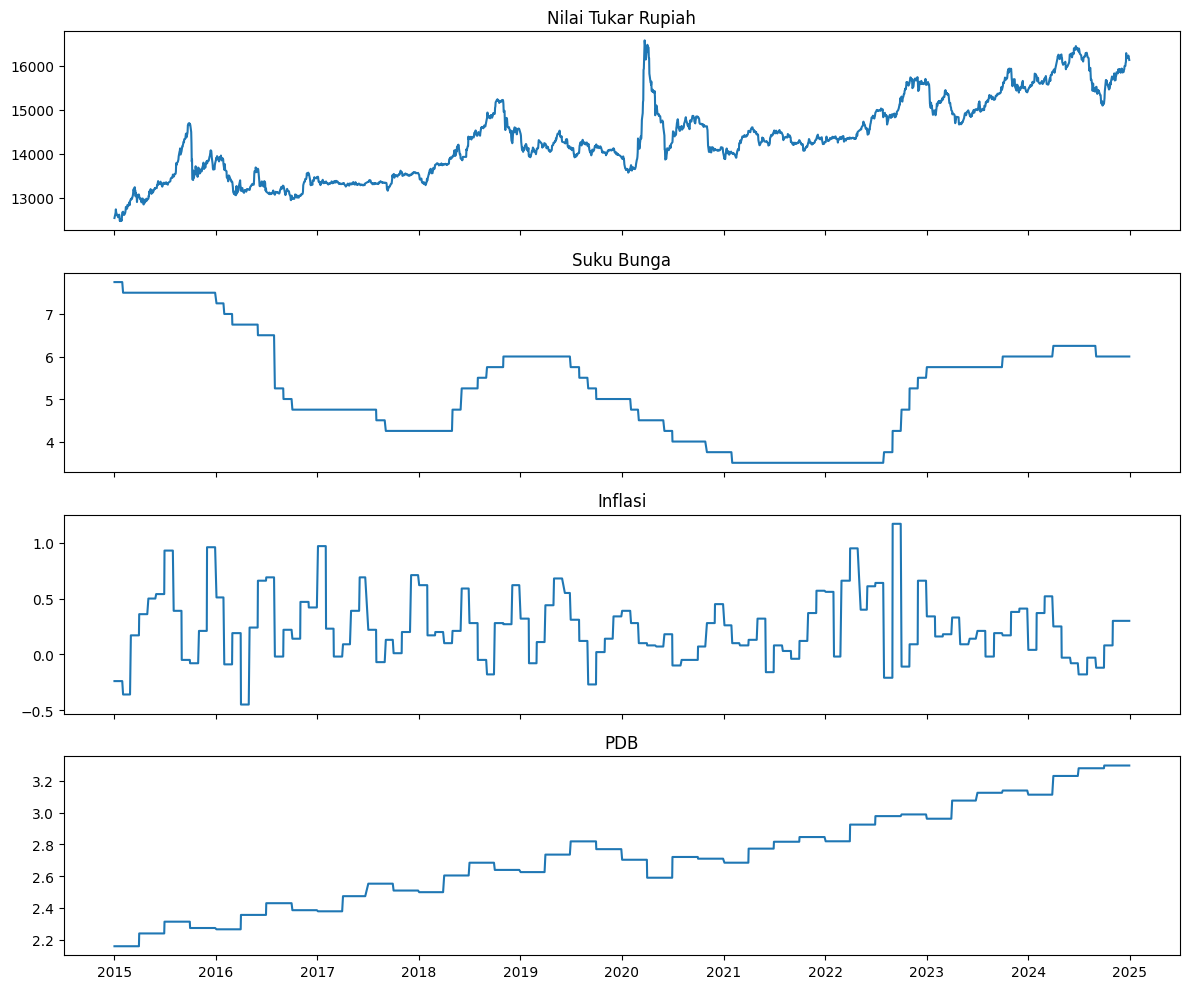

In [7]:
fig, axs = plt.subplots(4, 1, figsize=(12,10), sharex=True)

axs[0].plot(final_df["date"], final_df["nilai_tukar"])
axs[0].set_title("Nilai Tukar Rupiah")

axs[1].plot(final_df["date"], final_df["suku_bunga"])
axs[1].set_title("Suku Bunga")

axs[2].plot(final_df["date"], final_df["inflasi"])
axs[2].set_title("Inflasi")

axs[3].plot(final_df["date"], final_df["pdb"])
axs[3].set_title("PDB")

plt.tight_layout()
plt.show()

Variabel makroekonomi menunjukkan karakteristik perubahan yang relatif lebih
lambat dibandingkan IHSG, mencerminkan sifat indikator makro yang tidak
berfluktuasi secara harian.

#### Korelasi IHSG dan Variabel Makroekonomi

Matriks Korelasi

In [9]:
corr_matrix = final_df[
    ["ihsg", "pdb", "nilai_tukar", "suku_bunga", "inflasi"]
].corr()

corr_matrix

,ihsg,pdb,nilai_tukar,suku_bunga,inflasi
ihsg,1.000000,0.855050,0.620702,-0.243840,0.035263
pdb,0.855050,1.000000,0.871486,-0.232879,-0.074370
nilai_tukar,0.620702,0.871486,1.000000,-0.050329,-0.096458
suku_bunga,-0.243840,-0.232879,-0.050329,1.000000,-0.037689
inflasi,0.035263,-0.074370,-0.096458,-0.037689,1.000000


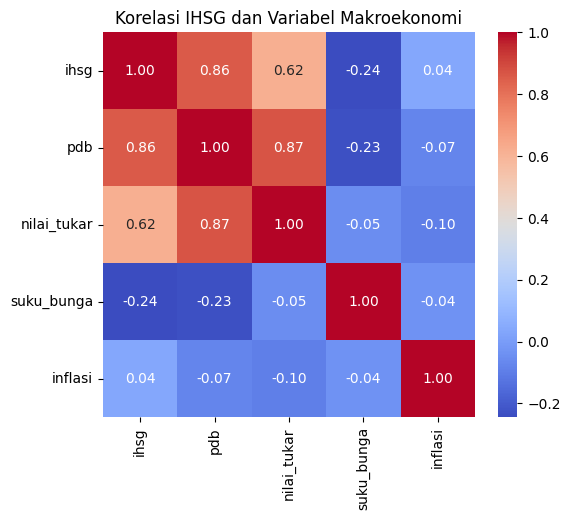

In [10]:
plt.figure(figsize=(6,5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Korelasi IHSG dan Variabel Makroekonomi")
plt.show()

Matriks di atas menunjukan korelasi pearson antara IHSG, PDB, Nilai tukar, Suku Bunga, dan Inflasi.

Nilai korelasi: <br>
+1 → hubungan positif kuat <br>
0  → hampir tidak ada hubungan <br>
–1 → hubungan negatif kuat <br>

Interpretasi per variabel terhadap IHSG
1. IHSG – PDB (0.86) → POSITIF KUAT
   Pertumbuhan ekonomi (PDB) sangat berkorelasi dengan kenaikan IHSG. Jika nilai PDB meningkat kemungkinan nilai IHSG akan ikut meningkat.
2. IHSG – Nilai Tukar (0.62) → POSITIF CUKUP KUAT
   

Melihat korelasi lain dari nilai tukar rupiah terhadap IHSG

In [40]:
# cari index IHSG tertinggi
idx_max_ihsg = final_df["ihsg"].idxmax()

# ambil baris data tersebut
max_row = final_df.loc[idx_max_ihsg]

max_row

date                  2024-09-19 00:00:00
ihsg                              7905.39
nilai_tukar                       15230.0
suku_bunga                            6.0
inflasi                             -0.12
pdb                               3.27951
rupiah_strength                  -15230.0
rupiah_menguat                   -15230.0
nilai_tukar_rupiah               -15230.0
Name: 2356, dtype: object

In [41]:
max_date = max_row["date"]
max_ihsg = max_row["ihsg"]
max_kurs = max_row["nilai_tukar"]

print("Tanggal IHSG tertinggi :", max_date)
print("Nilai IHSG tertinggi   :", max_ihsg)
print("Nilai tukar saat itu   :", max_kurs)

Tanggal IHSG tertinggi : 2024-09-19 00:00:00
Nilai IHSG tertinggi   : 7905.39
Nilai tukar saat itu   : 15230.0


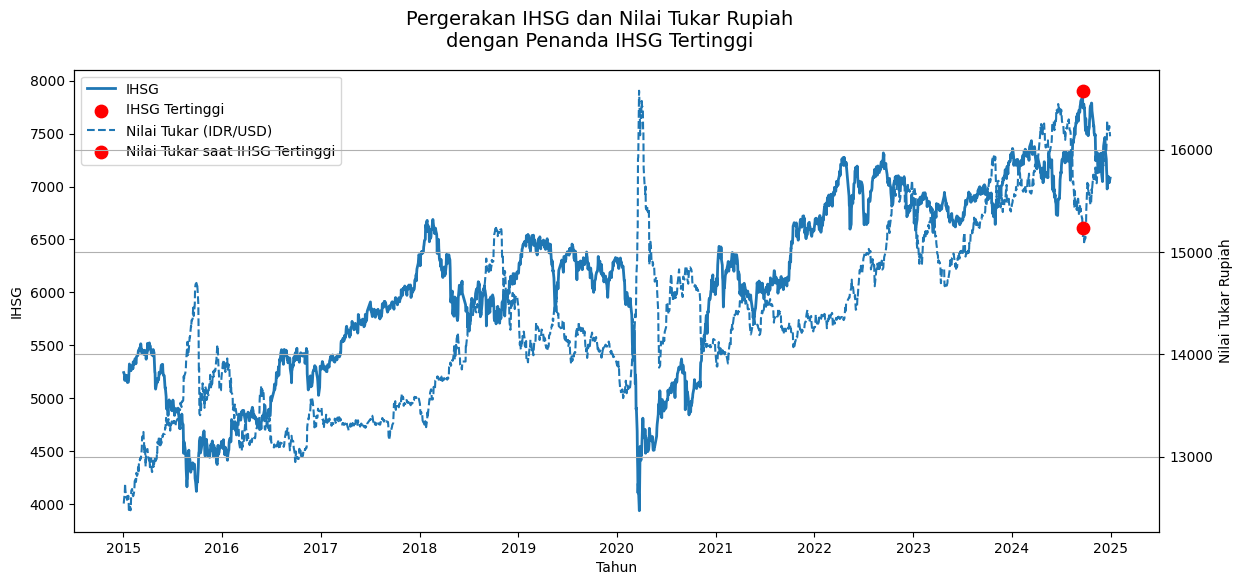

In [43]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14,6))

# === Plot IHSG (sumbu kiri) ===
ax1.plot(
    final_df["date"],
    final_df["ihsg"],
    label="IHSG",
    linewidth=2
)
ax1.set_xlabel("Tahun")
ax1.set_ylabel("IHSG")
ax1.tick_params(axis="y")

# === Tandai titik IHSG tertinggi ===
ax1.scatter(
    max_date,
    max_ihsg,
    color="red",
    s=80,
    zorder=5,
    label="IHSG Tertinggi"
)

# === Sumbu kanan untuk nilai tukar ===
ax2 = ax1.twinx()
ax2.plot(
    final_df["date"],
    final_df["nilai_tukar"],
    linestyle="--",
    label="Nilai Tukar (IDR/USD)"
)
ax2.set_ylabel("Nilai Tukar Rupiah")
ax2.tick_params(axis="y")

# === Tandai nilai tukar saat IHSG tertinggi ===
ax2.scatter(
    max_date,
    max_kurs,
    color="red",
    s=80,
    zorder=5,
    label="Nilai Tukar saat IHSG Tertinggi"
)

# === Judul & Legend ===
fig.suptitle(
    "Pergerakan IHSG dan Nilai Tukar Rupiah\n"
    "dengan Penanda IHSG Tertinggi",
    fontsize=14
)

# gabung legend dari dua axis
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.grid(True)
plt.show()

Correlation of First Difference (Δ)

In [34]:
df_diff_kurs = final_df[["date", "ihsg", "nilai_tukar"]].copy()

df_diff_kurs["ihsg_diff"] = df_diff_kurs["ihsg"].diff()
df_diff_kurs["nilai_tukar_diff"] = df_diff_kurs["nilai_tukar"].diff()

df_diff_kurs = df_diff_kurs.dropna()

In [35]:
corr_diff_kurs = df_diff_kurs[
    ["ihsg_diff", "nilai_tukar_diff"]
].corr()

corr_diff_kurs

,ihsg_diff,nilai_tukar_diff
ihsg_diff,1.000000,-0.364844
nilai_tukar_diff,-0.364844,1.000000


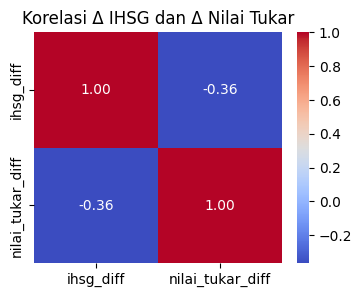

In [36]:
plt.figure(figsize=(4,3))
sns.heatmap(
    corr_diff_kurs,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Korelasi Δ IHSG dan Δ Nilai Tukar")
plt.show()

Rolling Correlation

In [28]:
rolling_corr = (
    final_df["ihsg"]
    .rolling(window=60)
    .corr(final_df["nilai_tukar"])
)

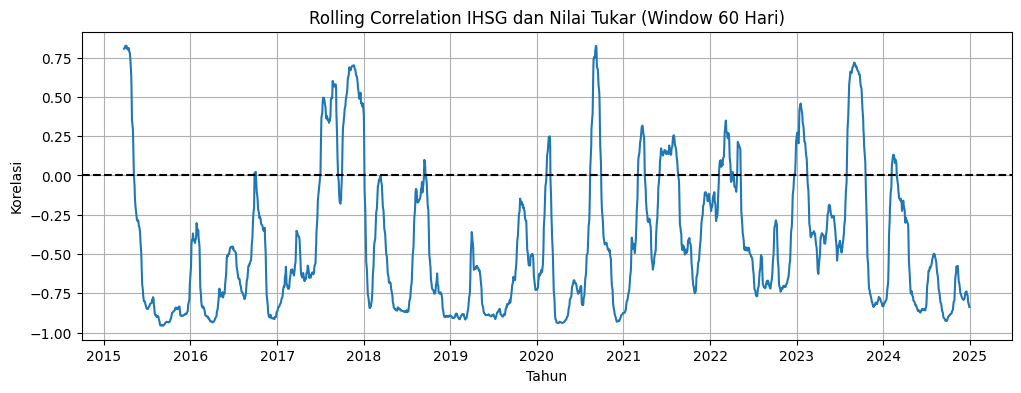

In [29]:
plt.figure(figsize=(12,4))
plt.plot(final_df["date"], rolling_corr)
plt.axhline(0, color="black", linestyle="--")
plt.title("Rolling Correlation IHSG dan Nilai Tukar (Window 60 Hari)")
plt.xlabel("Tahun")
plt.ylabel("Korelasi")
plt.grid(True)
plt.show()